In [ ]:
# Práctica 1 · Prototipo AE convolucional en escala de grises 
import glob
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [ ]:
# Carga de imágenes con el mismo patrón que la celda Evaluate created images de Create_Submission.ipynb
img_folder = "data/images"
imgs_arr = []
for img_path in sorted(glob.glob(img_folder + '/*.jpg')):
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    imgs_arr.append(img)
x = np.array(imgs_arr)
print(x.shape, x.dtype)

(30000, 64, 64) uint8


In [3]:
# Normalización y reshape siguiendo la estructura de los notebooks 2_2_1 (normalizar) y 2_2_2 (forma (alto, ancho, 1)) de Moodle
x = x.astype('float32') / 255.
x = np.reshape(x, (len(x), 64, 64, 1))
x_train, x_test = train_test_split(x, test_size=0.1, random_state=42)
print(x_train.shape)
print(x_test.shape)

(27000, 64, 64, 1)
(3000, 64, 64, 1)


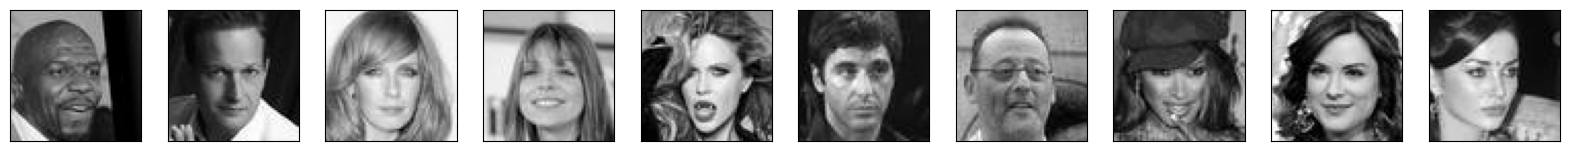

In [4]:
# Visualización con el bucle de imshow del notebook 2_2_1 de Moodle
n = 10
plt.figure(figsize=(20, 2))
for i in range(n):
    ax = plt.subplot(1, n, i + 1)
    plt.imshow(x_train[i].reshape(64, 64))
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
plt.show()

In [5]:
# Encoder convolucional siguiendo la estructura del notebook 2_2_2 de Moodle (Conv2D + MaxPooling2D)
# Flatten + Dense para el espacio latente (diapositiva 14 de Autoencoders)
import keras
from keras import layers

# Tamaño del espacio latente: 4096 píxeles -> 128 números (compresión de factor 32)
latent_dim = 128

# Encoder
input_img = keras.Input(shape=(64, 64, 1))

x = layers.Conv2D(16, (3, 3), activation='relu', padding='same')(input_img)
x = layers.MaxPooling2D((2, 2), padding='same')(x)
x = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(x)
x = layers.MaxPooling2D((2, 2), padding='same')(x)
x = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(x)
x = layers.MaxPooling2D((2, 2), padding='same')(x)
x = layers.Flatten()(x)
encoded = layers.Dense(latent_dim)(x)

encoder = keras.Model(input_img, encoded, name='encoder')
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       524,416 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 547,712 (2.09 MB)

 Trainable params: 547,712 (2.09 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# estructura notebook 2_2_2 de Moodle (Conv2D + UpSampling2D, salida sigmoid)
# Encoder y decoder notebook 2_3_1 de Moodle
latent_inputs = keras.Input(shape=(latent_dim,))

x = layers.Dense(8 * 8 * 64, activation='relu')(latent_inputs)
x = layers.Reshape((8, 8, 64))(x)
x = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(x)
x = layers.UpSampling2D((2, 2))(x)
x = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(x)
x = layers.UpSampling2D((2, 2))(x)
x = layers.Conv2D(16, (3, 3), activation='relu', padding='same')(x)
x = layers.UpSampling2D((2, 2))(x)
decoded = layers.Conv2D(1, (3, 3), activation='sigmoid', padding='same')(x)

decoder = keras.Model(latent_inputs, decoded, name='decoder')
decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4096)           │       528,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 64, 64, 1)      │           145 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 588,545 (2.25 MB)

 Trainable params: 588,545 (2.25 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# compile como en los notebooks 2_2_1 y 2_2_2 
autoencoder = keras.Model(input_img, decoder(encoder(input_img)), name='autoencoder')
autoencoder.compile(optimizer='adam', loss='binary_crossentropy')

In [ ]:
# fit siguiendo la estructura del notebook 2_2_1 
logs = autoencoder.fit(x_train, x_train,
                epochs=30,
                batch_size=128,
                shuffle=True,
                validation_data=(x_test, x_test),
                verbose=2)

Epoch 1/30
211/211 - 131s - 622ms/step - loss: 0.5768 - val_loss: 0.5501
Epoch 2/30
211/211 - 141s - 666ms/step - loss: 0.5461 - val_loss: 0.5407
Epoch 3/30
211/211 - 139s - 658ms/step - loss: 0.5403 - val_loss: 0.5375
Epoch 4/30
211/211 - 127s - 600ms/step - loss: 0.5374 - val_loss: 0.5349
Epoch 5/30
211/211 - 143s - 677ms/step - loss: 0.5355 - val_loss: 0.5335
Epoch 6/30
211/211 - 125s - 591ms/step - loss: 0.5343 - val_loss: 0.5325
Epoch 7/30
211/211 - 127s - 602ms/step - loss: 0.5333 - val_loss: 0.5317
Epoch 8/30
211/211 - 140s - 663ms/step - loss: 0.5326 - val_loss: 0.5310
Epoch 9/30
211/211 - 142s - 671ms/step - loss: 0.5318 - val_loss: 0.5305
Epoch 10/30
211/211 - 139s - 660ms/step - loss: 0.5313 - val_loss: 0.5301
Epoch 11/30
211/211 - 146s - 694ms/step - loss: 0.5309 - val_loss: 0.5295
Epoch 12/30
211/211 - 141s - 671ms/step - loss: 0.5306 - val_loss: 0.5303
Epoch 13/30
211/211 - 141s - 671ms/step - loss: 0.5300 - val_loss: 0.5289
Epoch 14/30
211/211 - 146s - 690ms/step - loss:

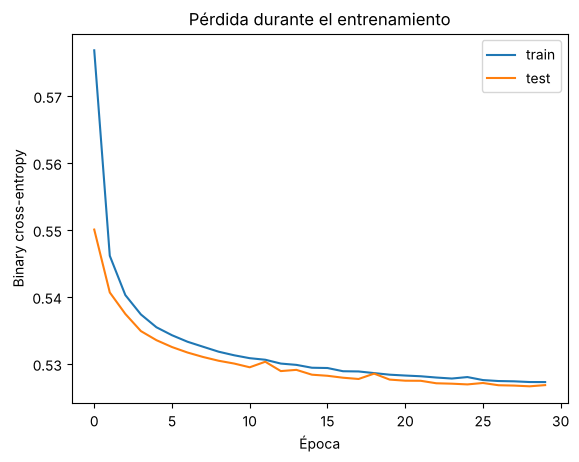

In [ ]:
# Curvas de entrenamiento como en el notebook 2_2_2
plt.plot(logs.history['loss'])
plt.plot(logs.history['val_loss'])
plt.title('Pérdida durante el entrenamiento')
plt.xlabel('Época')
plt.ylabel('Binary cross-entropy')
plt.legend(['train', 'test'])
plt.show()

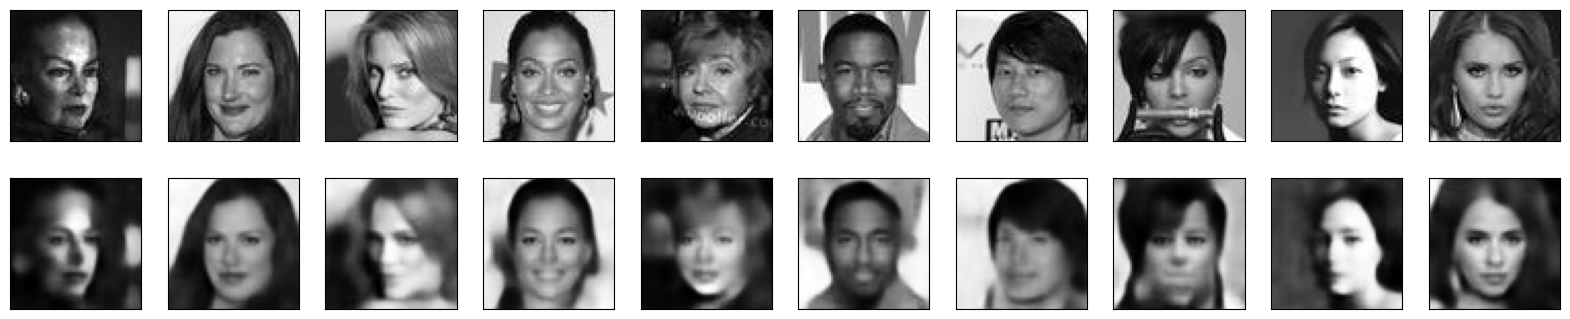

In [ ]:

decoded_imgs = autoencoder.predict(x_test, verbose=0)

n = 10
plt.figure(figsize=(20, 4))
for i in range(n):
    # Original
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i].reshape(64, 64))
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    # Reconstrucción
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(decoded_imgs[i].reshape(64, 64))
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
plt.show()

In [ ]:

encoded_train = encoder.predict(x_train, verbose=0)

media = encoded_train.mean(axis=0)
desviacion = encoded_train.std(axis=0)

print(encoded_train.shape)
print(media.shape, desviacion.shape)

(27000, 128)
(128,) (128,)


In [ ]:

n_images = 200

np.random.seed(42)
z_nuevos = np.random.normal(media, desviacion, size=(n_images, latent_dim))

generated_imgs = decoder.predict(z_nuevos, verbose=0)
print(generated_imgs.shape)

(200, 64, 64, 1)


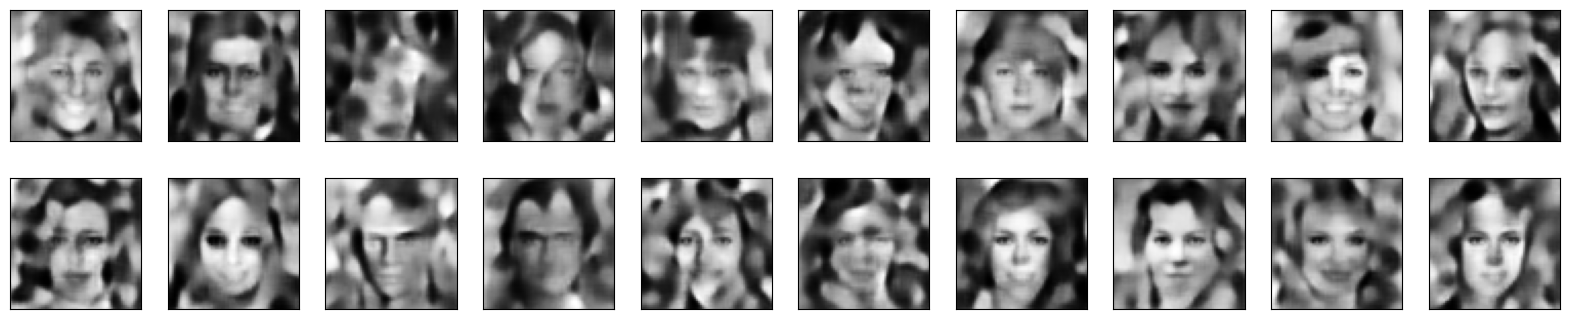

In [ ]:
# bucle de imshow del notebook 2_2_1
n = 10
plt.figure(figsize=(20, 4))
for i in range(2 * n):
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(generated_imgs[i].reshape(64, 64))
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
plt.show()

In [ ]:
# Guardar las caras generadas en PNG
from PIL import Image
import os

out_folder = "generated_imgs"
os.makedirs(out_folder, exist_ok=True)

for i in range(n_images):
    img = (generated_imgs[i].reshape(64, 64) * 255).astype(np.uint8)
    img = Image.fromarray(img, 'L')
    nombre_archivo = f"{out_folder}/img_{i+1:03d}.png"
    img.save(nombre_archivo)

In [ ]:

import glob
import cv2
import numpy as np
import pandas as pd

out_folder = "generated_imgs"


imgs_arr = []
for img_path in glob.glob(out_folder + '/*.png'):
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (64, 64), interpolation=cv2.INTER_AREA)
    imgs_arr.append(img.flatten())
df = pd.DataFrame(np.array(imgs_arr))


df.insert(0, "Usage", "Public")
df.insert(0, "ID", range(1, len(df) + 1))
# Create .csv
df.to_csv('submission.csv', index=False)
print(df.shape)

(200, 4098)
